# Práctica 3.6 Redes Neuronales
## Universidad Nacional Autónoma de México - Facultad de Ingeniería
## Minería de Datos - Gpo. 03 - Semestre 2027-1
### Autor: Lee Robles Leonardo Alan

---

## **1. Propósito de la práctica**

Diseñar, entrenar y validar una herramienta basada en Redes Neuronales Convolucionales (CNN) para detectar y clasificar software malicioso a través de un mapeo del código binario del malware a una imagen bidimensional utilizando herramientas de *Machine Learning* y el dataset "Malimg".

---

In [12]:
import os 
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## **2. Desarrollo de la práctica**

### 2.1 Análisis exploratorio (EDA) del dataset

#### 2.1.1 Escaneo del dataset y construcción del DataFrame de metadatos

In [13]:
files_registers = []

for root, dirs, files in os.walk('malimg_dataset'):
    for file in files:
        
        attributes = {}

        if not file.endswith('.png'):
            continue

        full_path = os.path.join(root, file)

        attributes['path'] = full_path
        attributes['size_kb'] = os.path.getsize(full_path) / (1024)
        attributes['family'] = os.path.basename(root)

        img = Image.open(full_path)

        attributes['width'] = img.width
        attributes['height'] = img.height
        attributes['resolution'] = (img.width, img.height)
        attributes['mode'] = img.mode

        files_registers.append(attributes)

EDA_df = pd.DataFrame(files_registers)

print(EDA_df)    

                                                   path     size_kb  \
0     malimg_dataset/Adialer.C/000bde2e9a94ba41c0c11...  130.629883   
1     malimg_dataset/Adialer.C/000e30a0819ac7ed931d6...  130.310547   
2     malimg_dataset/Adialer.C/002f06eff1d222560939b...  128.644531   
3     malimg_dataset/Adialer.C/0044f0746b812f6b454ce...  129.931641   
4     malimg_dataset/Adialer.C/0046a83d932a3d431eb21...  129.542969   
...                                                 ...         ...   
9334  malimg_dataset/Yuner.A/08a76fe7517aca8a28ece24...  326.180664   
9335  malimg_dataset/Yuner.A/08a9e75728b42c9b54a51f6...  326.180664   
9336  malimg_dataset/Yuner.A/08acb94708c0dbb3ba53f67...  326.180664   
9337  malimg_dataset/Yuner.A/08b0bf03f988fd2e1864e34...  326.180664   
9338  malimg_dataset/Yuner.A/08b53ab9f2a056a4e53534d...  326.180664   

         family  width  height  resolution mode  
0     Adialer.C    512     410  (512, 410)    L  
1     Adialer.C    512     409  (512, 409)    L

##### 2.1.1.1 Análisis de balance de clases

Utilizamos la función `.value_counts()` de Pandas para obtener el conteo total de imágenes por familia.

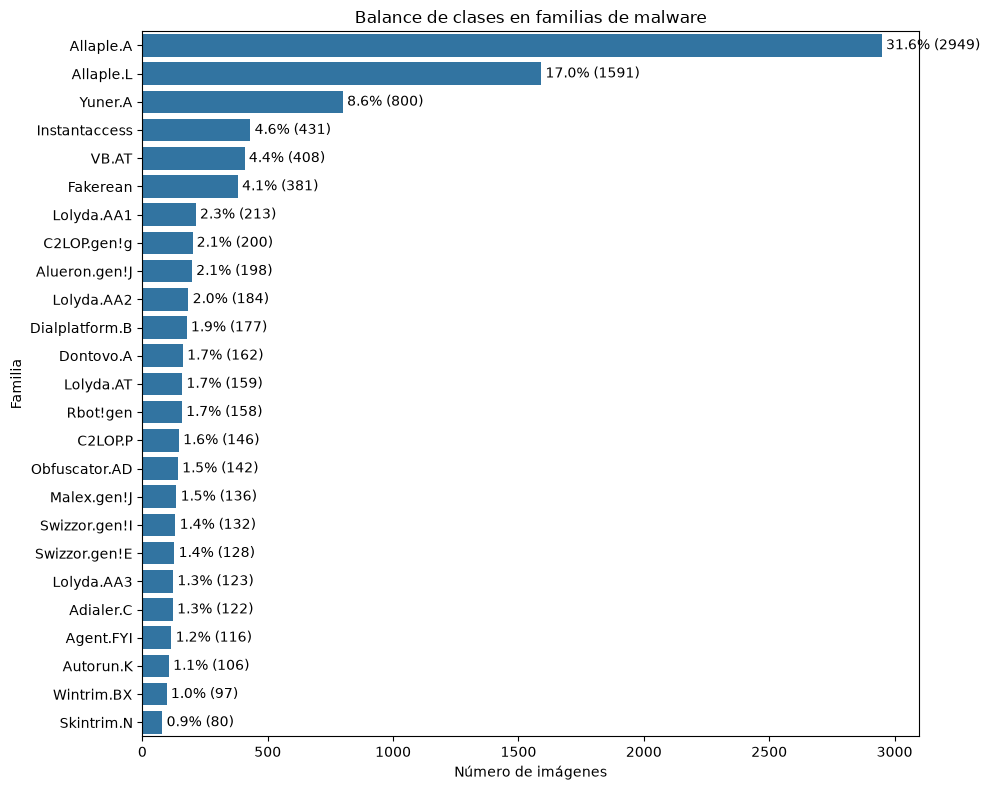

In [14]:
# Count the number of rows per family
counts = EDA_df.value_counts('family')

# Order the families by its size
fam_order = counts.index

# Create plot
plt.figure(figsize=(10,8))
ax = sns.countplot(data=EDA_df, y='family', order=fam_order)

# Calculate percentage
total_images = len(EDA_df)
percentages = [f'{(val / total_images) * 100:.1f}% ({val})' for val in counts]

# Assign labels
ax.bar_label(ax.containers[0], labels=percentages,padding=3)

plt.title('Balance de clases en familias de malware')
plt.xlabel('Número de imágenes')
plt.ylabel('Familia')

plt.tight_layout()
plt.show()

##### 2.1.1.2 Análisis de dimensiones, resoluciones y tamaños

El modelo solamente puede recibir entradas de tamaño fijo, por lo que si las imágenes del *dataset* son muy variadas en cuanto a resolución y tamaño, debemos tener en cuenta la re-escalación de la imagen, introduciendo pérdidas o ruido al modelo.

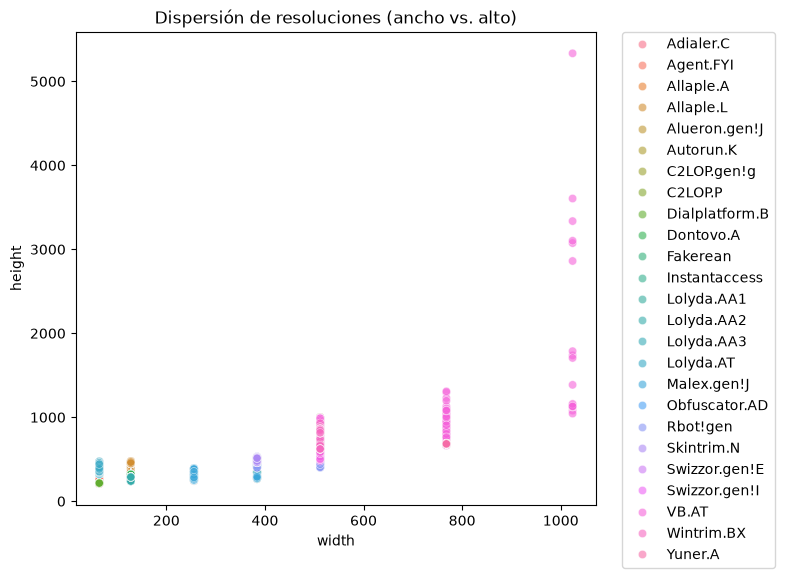

In [15]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=EDA_df, x='width', y='height', hue='family', alpha=0.6)

# To avoid the legend box to cover the plot
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left', borderaxespad=0.)

plt.title('Dispersión de resoluciones (ancho vs. alto)')
plt.tight_layout()
plt.show()

Esto nos indica que diferentes familias de Malware tienen diferentes resoluciones en las imágenes, lo que nos puede dar un indicio para clasificar. 

Ahora, para determinar hacia qué resolución normalizaremos todos las imágenes, observaremos la moda para el ancho y el alto. **Nota:** El ancho es una variable discreta, mientras que el alto es una variable continua.

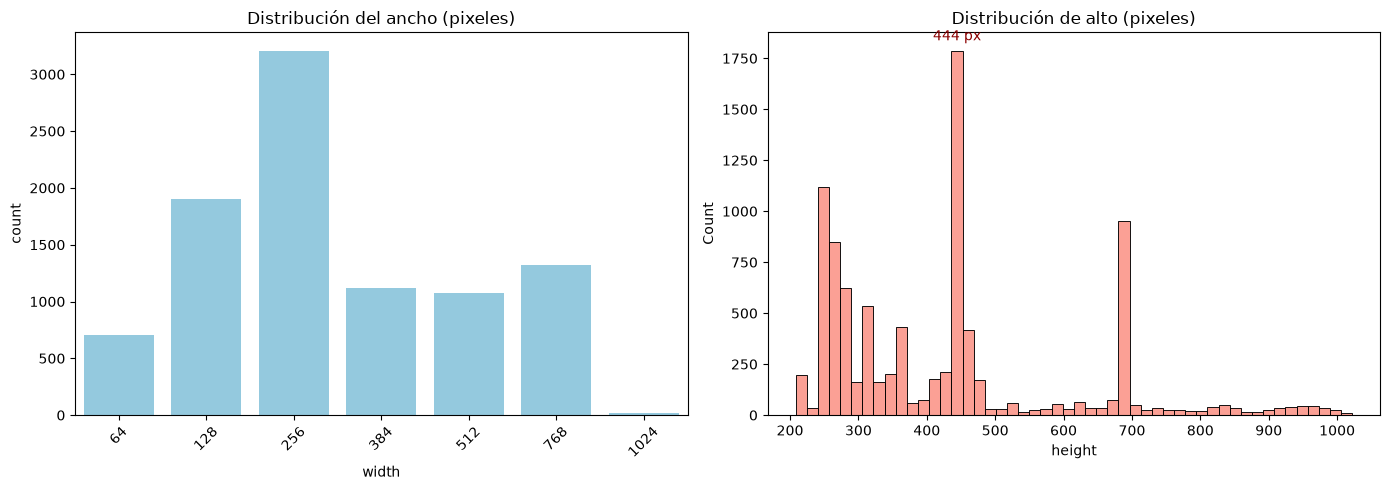

In [16]:
fig, axes = plt.subplots(1,2,figsize=(14,5))

# Width
sns.countplot(data=EDA_df, x='width', ax=axes[0], color='skyblue')
axes[0].set_title('Distribución del ancho (pixeles)')
axes[0].tick_params(axis='x', rotation=45)

# Height
sns.histplot(data=EDA_df[EDA_df['height'] <= 1024], x='height', bins=50, ax=axes[1], color='salmon')
axes[1].set_title('Distribución de alto (pixeles)')

max_patch = max(axes[1].patches, key=lambda p: p.get_height())

# Get the X mid point and the Y height peak
bin_center = max_patch.get_x() + (max_patch.get_width() / 2)
max_height = max_patch.get_height()

axes[1].annotate(
    f'{bin_center:.0f} px', 
    xy=(bin_center, max_height),
    xytext=(0, 5),
    textcoords='offset points',
    ha='center',
    va='bottom', 
    color='darkred'
)

plt.tight_layout()
plt.show()

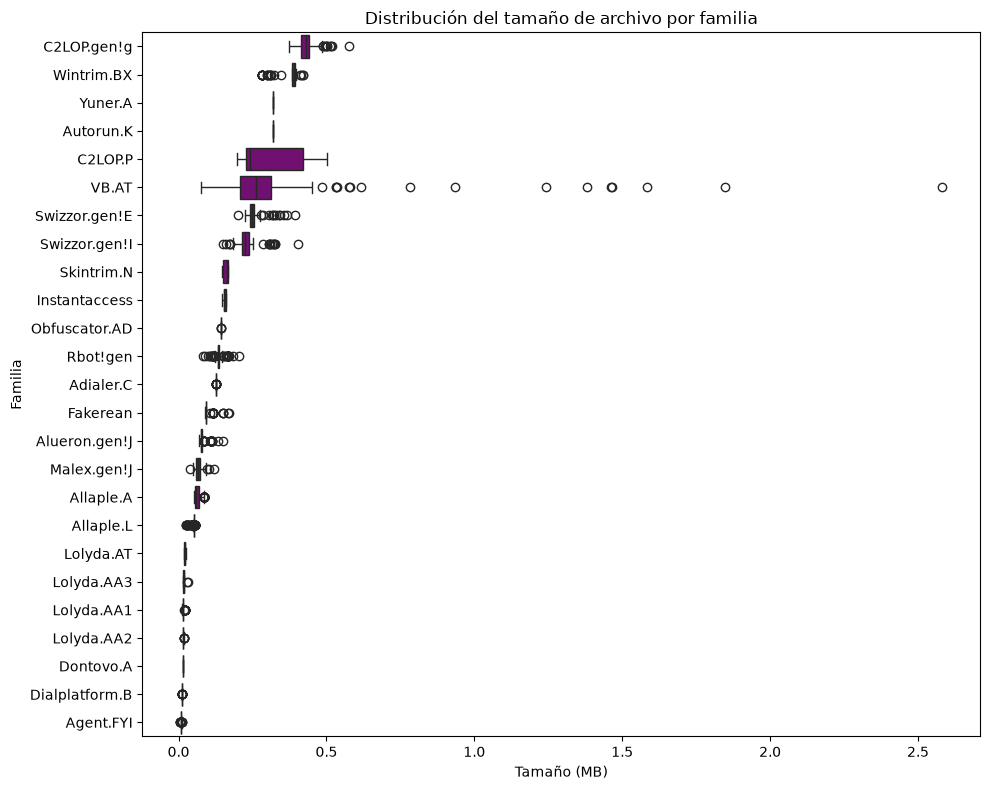

In [17]:
# Convert to MB
EDA_df['size_mb'] = EDA_df['size_kb'] / (1024)

# Calculate the average per family and sort ascendently
avg_sizes = EDA_df.groupby('family')['size_mb'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 8))

order_by_size = avg_sizes.index

sns.boxplot(data=EDA_df, y='family', x='size_mb', order=order_by_size, color='purple')

plt.title('Distribución del tamaño de archivo por familia')
plt.xlabel('Tamaño (MB)')
plt.ylabel('Familia')
plt.tight_layout()
plt.show()

##### 2.1.1.3 Matriz de subplots de imágenes reales

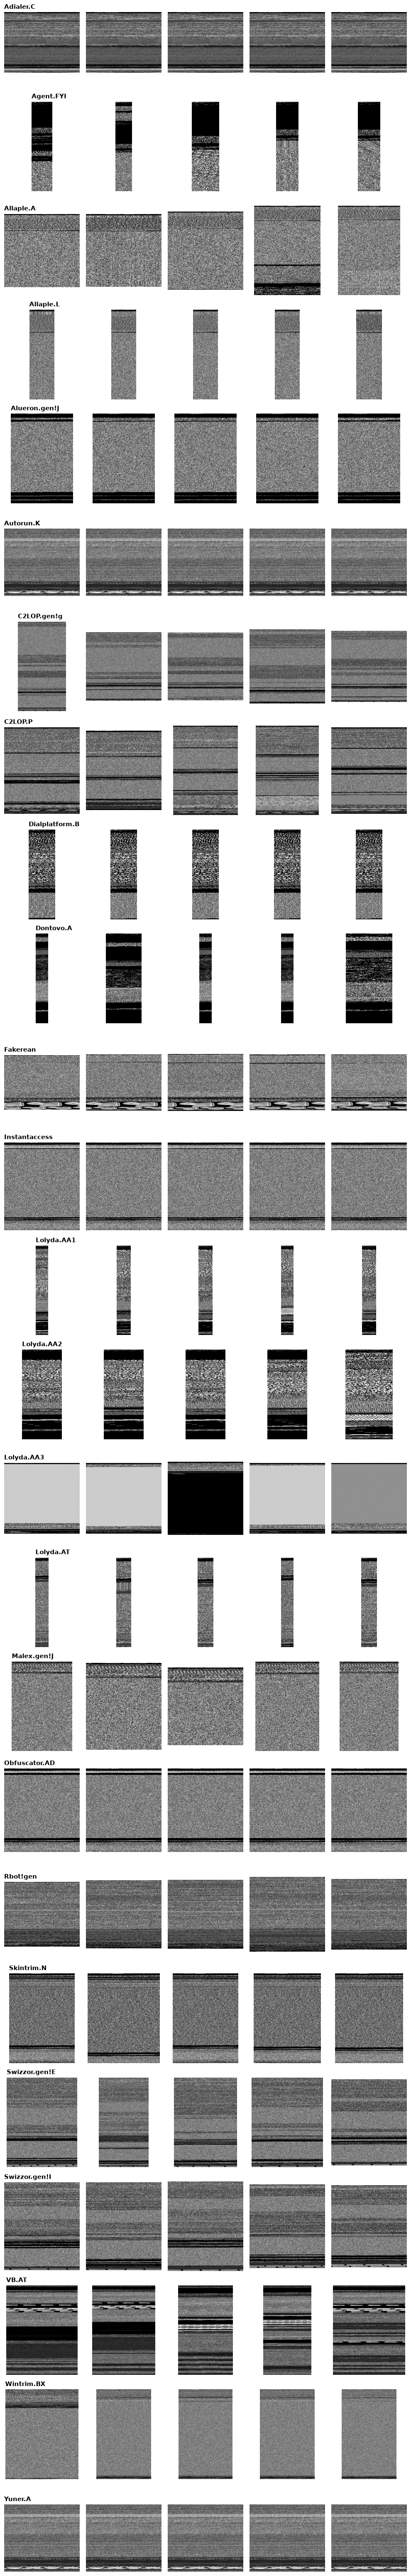

In [18]:
# Define the families to show and the samples per family
families_to_show = EDA_df['family'].unique() #Add [:3] to limit only 3 families.
samples_per_family = 5

# Create the subplots
fig, axes = plt.subplots(
    nrows=len(families_to_show), 
    ncols=samples_per_family, 
    figsize=(10, 2.5 * len(families_to_show))
)

# Iterate per family and render its images
for row_idx, family_name in enumerate(families_to_show):
    # Get the paths of the 'n' images from a family
    family_paths = EDA_df[EDA_df['family'] == family_name]['path'].sample(samples_per_family).values
    
    for col_idx in range(samples_per_family):
        ax = axes[row_idx, col_idx] if len(families_to_show) > 1 else axes[col_idx]
        
        # Load and display the images
        img_path = family_paths[col_idx]
        img = Image.open(img_path)
        
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        
        # Family name
        if col_idx == 0:
            ax.set_title(family_name, loc='left', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

##### 2.1.1.4 Distribución de intensidad de píxeles

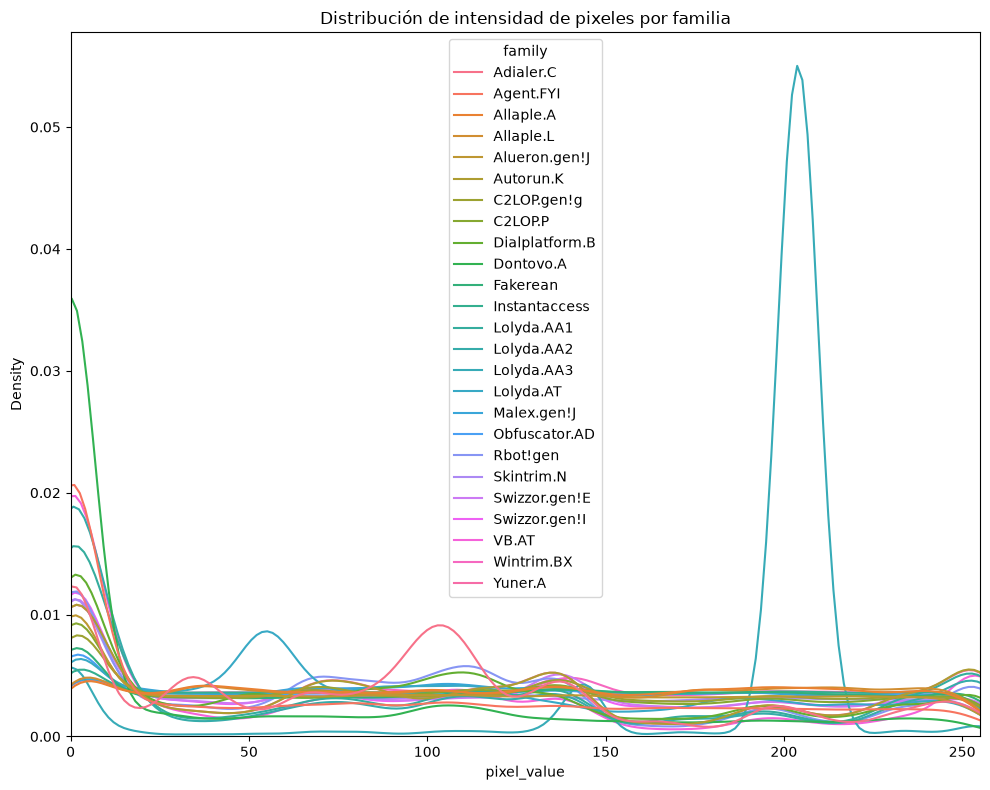

In [19]:
families_to_show = EDA_df['family'].unique() #Add [:3] to limit only 3 families.
samples_per_family = 15

pixel_data = []

for row_idx, family_name in enumerate(families_to_show):

    family_paths = EDA_df[EDA_df['family'] == family_name]['path'].sample(samples_per_family).values
    
    for col_idx in range(samples_per_family):

        img_path = family_paths[col_idx]
        img = Image.open(img_path).convert('L')

        img_matrix = np.asarray(img)
        img_vector = img_matrix.flatten()
        img_vector_sample = np.random.choice(img_vector, size = min(len(img_vector), 10000))

        df_temp = pd.DataFrame(
            {
                'pixel_value':img_vector_sample,
                'family': family_name 
            }
        )

        pixel_data.append(df_temp)

px_df = pd.concat(pixel_data, ignore_index=True)

plt.figure(figsize=(10,8))
sns.kdeplot(data=px_df, x='pixel_value', hue='family',common_norm=False)

plt.title('Distribución de intensidad de pixeles por familia')
plt.xlim(0,255)
plt.tight_layout()
plt.show()


        



### 2.2 Preparación de los datos

### 2.3 Entrenamiento del modelo

### 2.4 Validación del modelo

### 2.5 Pruebas y *testing* del modelo

---

## **3. Resultados**

---

## **4. Conclusiones de la práctica**

### Referencias

- Nataraj, L., Yegneswaran, V., Porras, P., & Zhang, X. (2011). Malware images: Visualization and automatic classification. En Proceedings of the 8th International Symposium on Visualization for Cyber Security (VizSec '11) (pp. 1–7). Association for Computing Machinery. https://dl.acm.org/doi/10.1145/2016904.2016908
